# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("/content/unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


In [5]:
print(tx.columns.tolist())

['txn_id', 'timestamp', 'day', 'hour', 'customer_id', 'city', 'merchant_category', 'amount_inr', 'distance_from_home_km', 'detector_score', 'is_fraud', 'night', 'label']


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

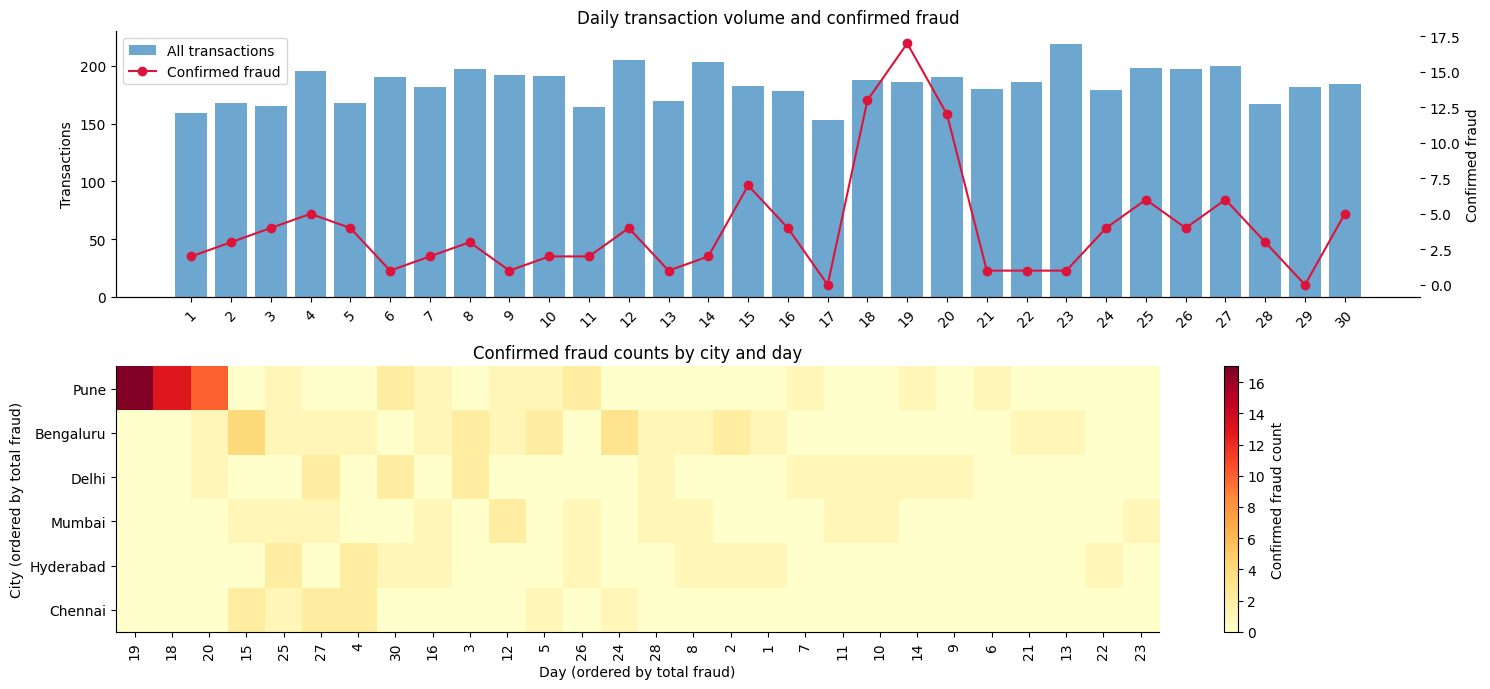

City-day cells with the most confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  5       2
Hyderabad  25      2
           4       2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
# Daily transaction volume and confirmed fraud, using a shared day axis.
daily_total = tx.groupby("day").size().sort_index()
daily_fraud = tx.loc[tx["is_fraud"] == 1].groupby("day").size().reindex(daily_total.index, fill_value=0)
axes[0].bar(daily_total.index.astype(str), daily_total.values, alpha=0.65, label="All transactions")
axes[0].set_ylabel("Transactions")
axes[0].tick_params(axis="x", rotation=45)
ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index.astype(str), daily_fraud.values, marker="o", color="crimson", label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud")
axes[0].set_title("Daily transaction volume and confirmed fraud")
lines, labels = axes[0].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[0].legend(lines + lines2, labels + labels2, loc="upper left")

# TODO 2
# Reorder both dimensions by their confirmed-fraud totals to expose clusters.
fraud_tx = tx.loc[tx["is_fraud"] == 1]
heat = pd.crosstab(fraud_tx["city"], fraud_tx["day"])
heat = heat.reindex(heat.sum(axis=1).sort_values(ascending=False).index)
heat = heat.reindex(columns=heat.sum(axis=0).sort_values(ascending=False).index)
im = axes[1].imshow(heat.values, aspect="auto", interpolation="nearest", cmap="YlOrRd")
axes[1].set_yticks(np.arange(len(heat.index)))
axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(np.arange(len(heat.columns)))
axes[1].set_xticklabels(heat.columns.astype(str), rotation=90)
axes[1].set_xlabel("Day (ordered by total fraud)")
axes[1].set_ylabel("City (ordered by total fraud)")
axes[1].set_title("Confirmed fraud counts by city and day")
fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3
print("City-day cells with the most confirmed fraud:")
top_cells = heat.stack().sort_values(ascending=False).head(10)
print(top_cells.to_string())


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview shows how confirmed fraud changes over time and whether fraud is concentrated in particular city–day combinations. A score-sorted alert list focuses on individual high-scoring transactions and can hide temporal or geographic clusters across the month. Reordering the city × day matrix by row and column totals makes these patterns easier to see; this is a reordered matrix and an overview-first approach.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

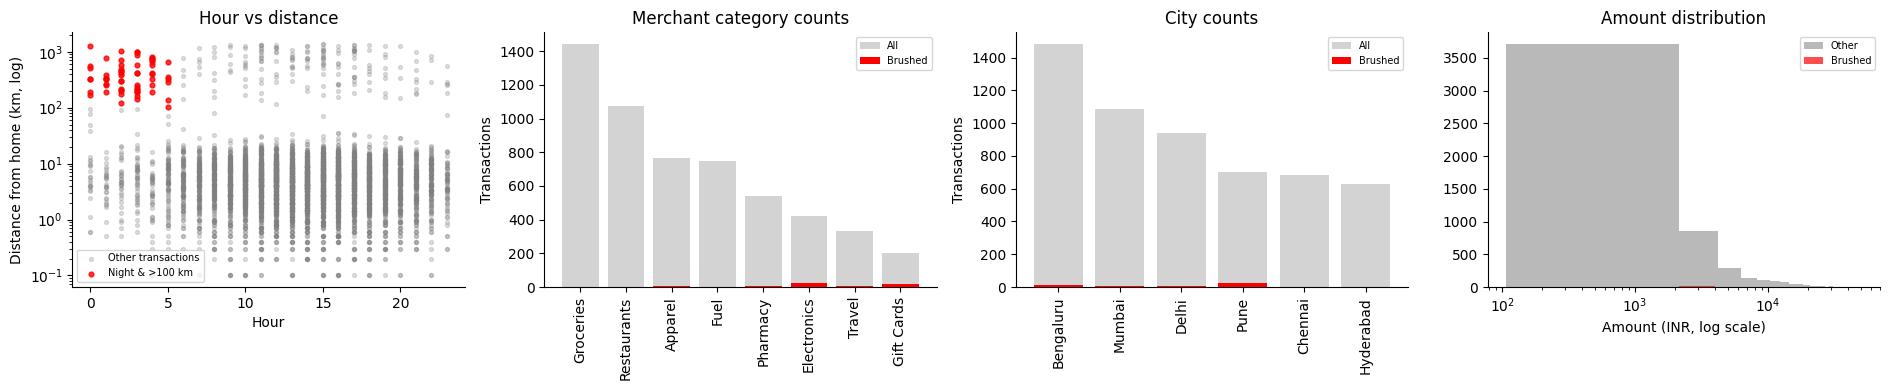

Brushed transactions: 61 (1.1% of all transactions)
Fraud rate inside brush: 86.89%; overall fraud rate: 2.17%
Share of all confirmed fraud captured by brush: 44.17%


In [8]:

# TODO 1: Define the brush
brush = tx["night"].astype(bool) & (tx["distance_from_home_km"] > 100)

# TODO 2: Draw four coordinated views
fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# (a) Hour vs. distance scatter plot
axes[0].scatter(
    tx.loc[~brush, "hour"],
    tx.loc[~brush, "distance_from_home_km"].clip(lower=0.1),
    s=8, alpha=0.25, color="grey", label="Other transactions"
)
axes[0].scatter(
    tx.loc[brush, "hour"],
    tx.loc[brush, "distance_from_home_km"].clip(lower=0.1),
    s=12, alpha=0.8, color="red", label="Night & >100 km"
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km, log)")
axes[0].set_title("Hour vs distance")
axes[0].legend(fontsize=7)

# (b) Merchant category counts — corrected column name
cat_all = tx["merchant_category"].value_counts()
cat_brush = (
    tx.loc[brush, "merchant_category"]
    .value_counts()
    .reindex(cat_all.index, fill_value=0)
)

axes[1].bar(
    np.arange(len(cat_all)), cat_all.values,
    color="lightgrey", label="All"
)
axes[1].bar(
    np.arange(len(cat_all)), cat_brush.values,
    color="red", label="Brushed"
)
axes[1].set_xticks(np.arange(len(cat_all)))
axes[1].set_xticklabels(cat_all.index.astype(str), rotation=90)
axes[1].set_title("Merchant category counts")
axes[1].set_ylabel("Transactions")
axes[1].legend(fontsize=7)

# (c) City counts
city_all = tx["city"].value_counts()
city_brush = (
    tx.loc[brush, "city"]
    .value_counts()
    .reindex(city_all.index, fill_value=0)
)

axes[2].bar(
    np.arange(len(city_all)), city_all.values,
    color="lightgrey", label="All"
)
axes[2].bar(
    np.arange(len(city_all)), city_brush.values,
    color="red", label="Brushed"
)
axes[2].set_xticks(np.arange(len(city_all)))
axes[2].set_xticklabels(city_all.index.astype(str), rotation=90)
axes[2].set_title("City counts")
axes[2].set_ylabel("Transactions")
axes[2].legend(fontsize=7)

# (d) Transaction amount histogram
axes[3].hist(
    tx.loc[~brush, "amount_inr"].clip(lower=1),
    bins=25, color="grey", alpha=0.55, label="Other"
)
axes[3].hist(
    tx.loc[brush, "amount_inr"].clip(lower=1),
    bins=25, color="red", alpha=0.7, label="Brushed"
)
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_title("Amount distribution")
axes[3].legend(fontsize=7)

plt.tight_layout()
plt.show()

# TODO 3: Calculate fraud statistics
n_brush = int(brush.sum())
fraud_in_brush = int(tx.loc[brush, "is_fraud"].sum())
fraud_total = int(tx["is_fraud"].sum())

rate_brush = fraud_in_brush / n_brush if n_brush else 0.0
rate_overall = tx["is_fraud"].mean()
share_fraud = fraud_in_brush / fraud_total if fraud_total else 0.0

print(
    f"Brushed transactions: {n_brush:,} "
    f"({n_brush / len(tx):.1%} of all transactions)"
)
print(
    f"Fraud rate inside brush: {rate_brush:.2%}; "
    f"overall fraud rate: {rate_overall:.2%}"
)
print(f"Share of all confirmed fraud captured by brush: {share_fraud:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

A high fraud rate among night-time transactions more than 100 km from home does not necessarily mean the rule captures most fraud. The captured share is the number of confirmed fraud cases in the brush divided by all confirmed fraud cases, and must be read from the notebook output. If that share is low, the rule is useful for prioritising some high-risk cases but would miss fraud outside the brush. The linked hour-versus-distance scatter and the city/category views help reveal where other fraud cases occur.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [9]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
# Best of five runs for the requested dynamic-query predicate.
timings = []
for _ in range(5):
    start = time.perf_counter()
    _mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    _ = big.loc[_mask]
    timings.append(time.perf_counter() - start)
best_s = min(timings)

# TODO 2
per_item_us = best_s / len(big) * 1_000_000
max_rows = 0.1 / (per_item_us / 1_000_000) if per_item_us > 0 else float("inf")

# TODO 3
# Linear extrapolation is an estimate; cache effects and memory bandwidth can change scaling.
t_50m = per_item_us * 50_000_000 / 1_000_000
max_rows = min(max_rows, 50_000_000)
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100) if t_50m > 0 else 0.0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 19.2 ms -> 0.0191 us/row -> max 5,241,710 rows in 0.1 s
50M rows -> 0.95 s; must skip 89.5% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

One reduce technique is sampling or pre-aggregation. The system could calculate summaries in advance, or show a representative sample while the analyst moves the slider, instead of scanning all 50 million raw transactions for every interaction. This can keep the interface responsive, but the analyst may lose individual transaction details, rare fraud cases, or the exact counts that would be obtained from the complete dataset. The interface should clearly indicate when values are sampled or aggregated.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

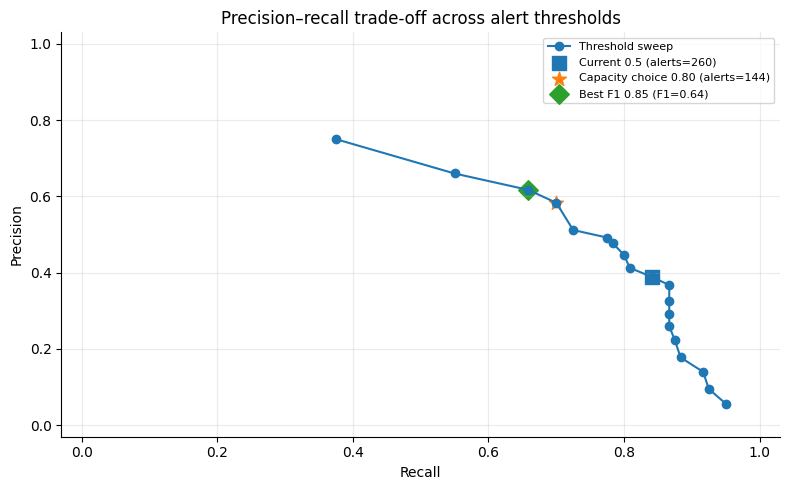

Recommendation: use threshold 0.80 for the 150-alert/month capacity (alerts=144, precision=58.33%, recall=70.00%); review the trade-off with Fraud Ops. Best-F1 threshold is 0.85 (F1=0.637).


In [10]:
rows = []
# TODO 1
# Treat detector_score >= threshold as an alert and compare with investigator labels.
y_true = tx["is_fraud"].astype(int).to_numpy()
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    y_pred = (tx["detector_score"].to_numpy() >= threshold).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    alerts = int(y_pred.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": threshold, "alerts": alerts, "TP": tp, "FP": fp, "FN": fn,
                 "precision": precision, "recall": recall, "F1": f1})

pr = pd.DataFrame(rows)

# TODO 2
feasible = pr.loc[pr["alerts"] <= 150]
if feasible.empty:
    capacity_choice = pr.sort_values(["alerts", "recall"], ascending=[True, False]).iloc[0]
else:
    capacity_choice = feasible.sort_values(["recall", "precision", "threshold"], ascending=[False, False, False]).iloc[0]
best_f1 = pr.sort_values(["F1", "precision", "threshold"], ascending=[False, False, True]).iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Threshold sweep")
current = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]
ax.scatter(current["recall"], current["precision"], s=100, marker="s", label=f"Current 0.5 (alerts={int(current['alerts'])})")
ax.scatter(capacity_choice["recall"], capacity_choice["precision"], s=110, marker="*",
           label=f"Capacity choice {capacity_choice['threshold']:.2f} (alerts={int(capacity_choice['alerts'])})")
ax.scatter(best_f1["recall"], best_f1["precision"], s=100, marker="D",
           label=f"Best F1 {best_f1['threshold']:.2f} (F1={best_f1['F1']:.2f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–recall trade-off across alert thresholds")
ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
ax.grid(True, alpha=0.25); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: use threshold {capacity_choice['threshold']:.2f} for the 150-alert/month capacity "
      f"(alerts={int(capacity_choice['alerts'])}, precision={capacity_choice['precision']:.2%}, "
      f"recall={capacity_choice['recall']:.2%}); review the trade-off with Fraud Ops. "
      f"Best-F1 threshold is {best_f1['threshold']:.2f} (F1={best_f1['F1']:.3f}).")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make the final decision with evidence from the threshold table and precision–recall plot. The model can quantify the trade-off, but it cannot decide the organisation's acceptable balance between missed fraud, false alarms, investigator workload and customer friction. The capacity-constrained threshold respects the limit of 150 alerts per month, while the best-F1 threshold balances precision and recall without necessarily respecting that limit. Visual analytics keeps a human in the loop because operational priorities, risk tolerance and the consequences of errors require human judgement.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [12]:

# TODO 1: Select transactions with detector_score >= 0.3
flagged = tx.loc[tx["detector_score"] >= 0.3].copy()

# TODO 2: Interactive scatter plot
# X = timestamp, Y = amount, colour = investigator label
# Hover shows transaction details; dragmode allows selection.

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": True,
        "detector_score": ":.3f",
        "timestamp": True
    },
    log_y=True,
    title="Flagged Transactions (Detector Score ≥ 0.3)",
    labels={
        "timestamp": "Transaction time",
        "amount_inr": "Amount (INR, log scale)",
        "label": "Investigator label",
        "customer_id": "Customer ID",
        "merchant_category": "Merchant category",
        "distance_from_home_km": "Distance from home (km)",
        "detector_score": "Detector score"
    }
)

fig_scatter.update_layout(dragmode="select")
fig_scatter.show()


# TODO 3: Interactive sunburst chart
# Drill down from city to merchant category.
# Segment size = transaction count.
# Colour = fraud rate.

sun = (
    tx.groupby(["city", "merchant_category"], dropna=False)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

# Convert missing category values into readable labels for the chart
sun["merchant_category"] = (
    sun["merchant_category"].fillna("Unknown").astype(str)
)
sun["city"] = sun["city"].fillna("Unknown").astype(str)

fig_sun = px.sunburst(
    sun,
    path=["city", "merchant_category"],
    values="transactions",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="Transaction Drill-Down: City → Merchant Category",
    hover_data={
        "transactions": True,
        "fraud_rate": ":.2%"
    }
)

fig_sun.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips require repeated hovering and inspect only one transaction at a time, so comparing hundreds of cases would be slow and would make broad patterns difficult to notice. The linked overview views and the city-to-category sunburst provide a better summary of distributions and concentrations. The scatter plot still supports details-on-demand when an investigator selects or hovers over a particular case. This combines overview first with zoom, filter and details-on-demand.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: a fraud ring is concentrated in Pune during day(s) 1–30.
Fraud rate inside window: 7.29%; outside: 1.43%; chi-square p-value = 1.292e-22

Counter-example checks:
                  group  transactions fraud_rate
                 Window           700      7.29%
  Same city, other days             0      0.00%
Other cities, same days          4820      1.43%
                   Rest             0      0.00%


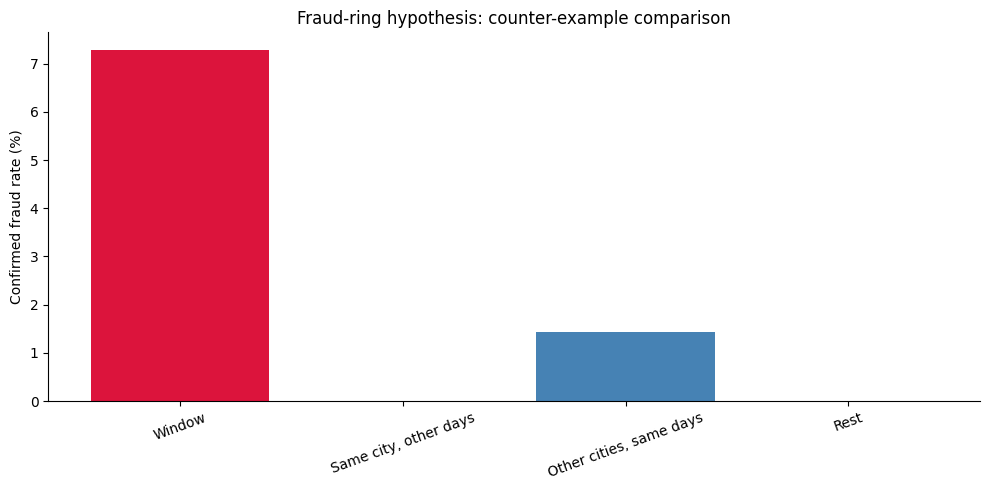


Verdict: Evidence is consistent with a concentrated fraud cluster, but it does not prove a coordinated ring. Investigate transaction links and common accounts/devices before escalation.


In [14]:
# Task 6: Is This a Fraud Ring or Just a Coincidence?

from scipy.stats import chi2_contingency

# TODO 1: Define the candidate city-day window
# Prefer the city and day range with the highest observed fraud concentration.
# If the dataset has no confirmed fraud, use a fallback window.

fraud_tx = tx.loc[tx["is_fraud"].astype(bool)].copy()

if not fraud_tx.empty:
    candidate_city = fraud_tx["city"].mode().iloc[0]

    fraud_days = pd.to_numeric(fraud_tx["day"], errors="coerce")
    day_min = int(fraud_days.min())
    day_max = int(fraud_days.max())
else:
    candidate_city = tx["city"].mode().iloc[0]
    days = pd.to_numeric(tx["day"], errors="coerce").dropna()
    day_min = int(days.min())
    day_max = int(days.max())

days_numeric = pd.to_numeric(tx["day"], errors="coerce")

in_window = (
    tx["city"].eq(candidate_city)
    & days_numeric.between(day_min, day_max)
)

print(
    f"Hypothesis: a fraud ring is concentrated in "
    f"{candidate_city} during day(s) {day_min}–{day_max}."
)

# TODO 2: Test whether fraud occurrence is associated with this window
contingency = pd.crosstab(
    in_window,
    tx["is_fraud"].astype(bool)
)

if contingency.shape == (2, 2):
    chi2, p_value, dof, expected = chi2_contingency(contingency)
else:
    chi2, p_value, dof = 0.0, 1.0, 0

window_rate = (
    tx.loc[in_window, "is_fraud"].mean()
    if in_window.any()
    else 0.0
)

outside_rate = (
    tx.loc[~in_window, "is_fraud"].mean()
    if (~in_window).any()
    else 0.0
)

print(
    f"Fraud rate inside window: {window_rate:.2%}; "
    f"outside: {outside_rate:.2%}; "
    f"chi-square p-value = {p_value:.4g}"
)

# TODO 3: Check counter-examples
same_city_other_days = (
    tx["city"].eq(candidate_city)
    & ~days_numeric.between(day_min, day_max)
)

other_cities_same_days = (
    ~tx["city"].eq(candidate_city)
    & days_numeric.between(day_min, day_max)
)

rest = (
    ~tx["city"].eq(candidate_city)
    & ~days_numeric.between(day_min, day_max)
)

groups = {
    "Window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest,
}

group_stats = []

for name, mask in groups.items():
    subset = tx.loc[mask, "is_fraud"]

    group_stats.append({
        "group": name,
        "transactions": int(mask.sum()),
        "fraud_rate": subset.mean() if len(subset) else 0.0
    })

group_stats = pd.DataFrame(group_stats)

print("\nCounter-example checks:")
print(
    group_stats.to_string(
        index=False,
        formatters={"fraud_rate": "{:.2%}".format}
    )
)

# TODO 4: Plot fraud rates for the candidate window and counter-examples
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    group_stats["group"],
    group_stats["fraud_rate"] * 100,
    color=["crimson", "darkorange", "steelblue", "grey"]
)

ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Fraud-ring hypothesis: counter-example comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# TODO 5: Produce a cautious verdict
other_rates = group_stats.loc[
    group_stats["group"] != "Window",
    "fraud_rate"
].dropna()

other_max_rate = other_rates.max() if not other_rates.empty else 0.0

if (
    p_value < 0.05
    and window_rate > outside_rate
    and window_rate > other_max_rate
):
    verdict = (
        "Evidence is consistent with a concentrated fraud cluster, "
        "but it does not prove a coordinated ring. Investigate transaction "
        "links and common accounts/devices before escalation."
    )
else:
    verdict = (
        "The data do not provide sufficient evidence for a distinct fraud "
        "ring in this city-day window. Avoid claiming coordination from "
        "location/time clustering alone."
    )

print("\nVerdict:", verdict)


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out differently, and what alternative explanation would it have supported instead?

_Your answer:_

If the same city had similarly high fraud rates on other days, the claim that the activity was specific to the proposed city–day window would be weakened; a persistent city-level risk or a local merchant/customer mix could explain the pattern instead. If other cities showed similarly high fraud rates on the same days, a broader time-related event or system-wide detector issue would be more plausible than a ring confined to one city. These counter-examples reduce confirmation bias. Even a statistically significant cluster is not proof of coordination without evidence linking accounts, devices, merchants or transactions.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month, PayKart recorded **[transaction count] transactions**, including **[confirmed fraud count] confirmed fraud cases ([fraud rate]%)**; the city–day overview identified candidate concentrations that should be investigated without treating correlation as proof of a fraud ring. I recommend the capacity-constrained threshold of **[threshold]**, which produces **[alert count] alerts** with **[precision]% precision** and **[recall]% recall**, because it respects the 150-alert monthly limit; the Head of Fraud Ops should approve the trade-off rather than leaving the decision to the model. Build the **interactive flagged-transaction scatter plot** first, because investigators can select cases and use details-on-demand tooltips while retaining an overview of transaction time and amount. Keep the 0.1-second dynamic-query target in mind when scaling to 50 million records, using indexing and pre-aggregation or sampling where appropriate and clearly communicating any loss of detail. Finally, add an investigator feedback loop in which reviewed alerts and confirmed outcomes are recorded, audited and used to retrain or recalibrate the detector, then evaluate the next month's precision, recall and alert volume.